# 01 — Exploratory Data Analysis (EDA)

Tujuan: memahami data **sebelum** membuat model. Pertanyaan yang ingin dijawab:
1. Kolom apa saja yang ada, dan mana yang boleh dipakai?
2. Seimbangkah jumlah komentar judol vs normal?
3. Adakah duplikat?
4. Apa ciri khas komentar judol yang bisa dijadikan *feature*?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # agar `import src` bisa jalan dari folder notebooks/
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DATA_PATH
from src.preprocessing import load_data, clean_data, feature_engineering, normalize_text
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid')

## 1. Lihat data mentah

In [2]:
raw = load_data(DATA_PATH)
print(raw.shape)
raw.head()

(10230, 9)


,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10230 entries, 0 to 10229
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   video_id         10230 non-null  str  
 1   title            10230 non-null  str  
 2   channel_name     10230 non-null  str  
 3   tanggal          10230 non-null  str  
 4   author           10230 non-null  str  
 5   komentar         10230 non-null  str  
 6   label            10230 non-null  int64
 7   komentar_clean   10230 non-null  str  
 8   predicted_label  10230 non-null  int64
dtypes: int64(2), str(7)
memory usage: 719.4 KB


**Perhatikan kolom `predicted_label`.** Ini hasil prediksi model orang lain. Seberapa mirip dengan `label`?

In [4]:
(raw['label'] == raw['predicted_label']).mean()

np.float64(0.9915933528836754)

99% sama → kalau dipakai sebagai feature, model kita "menyontek" jawaban. Ini disebut **data leakage**. Kolom ini (dan `komentar_clean`, karena kita mau membuat pembersihan sendiri) dibuang di `clean_data()`.

## 2. Duplikat

In [5]:
dup = raw[raw['komentar'].duplicated(keep=False)]
print('baris duplikat:', raw['komentar'].duplicated().sum())
raw.groupby('label')['komentar'].apply(lambda s: s.duplicated().mean()).rename('rasio duplikat')

baris duplikat: 1229


label
0    0.000332
1    0.291281
Name: rasio duplikat, dtype: float64

Komentar judol jauh lebih sering duplikat (bot spam copy-paste). Kalau tidak dibuang, komentar yang sama bisa masuk ke train **dan** test → skor test terlihat bagus padahal model hanya menghafal.

In [6]:
df = feature_engineering(clean_data(raw))
print(df.shape)
df['label'].value_counts()

(9001, 14)


label
0    6018
1    2983
Name: count, dtype: int64

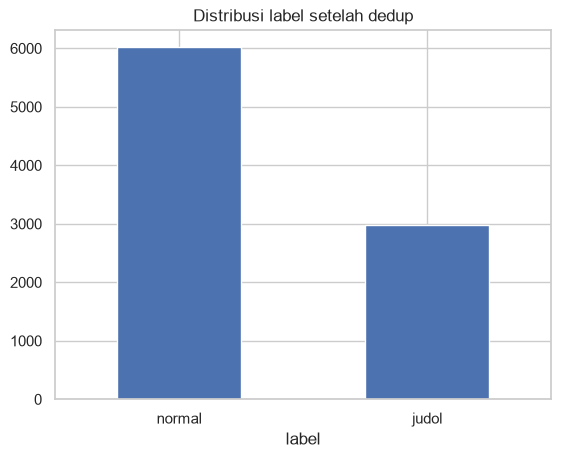

In [7]:
ax = df['label'].map({0: 'normal', 1: 'judol'}).value_counts().plot.bar(rot=0)
ax.set_title('Distribusi label setelah dedup');

Rasio ~2:1, tidak terlalu timpang, tapi cukup untuk membuat **accuracy menyesatkan** — model yang selalu menebak "normal" sudah dapat ~67%. Karena itu kita fokus ke **precision, recall, F1**.

## 3. Trik penyamaran spammer

In [8]:
df[df['label'] == 1][['komentar', 'text_norm']].sample(12, random_state=0)

,komentar,text_norm
45,kebanggaan gua nih kalau di tongkrongan! ⭐ A L E X I S 1 7 ⭐Top markotop,kebanggaan gua nih kalau di tongkrongan! ⭐ alexis17 ⭐top markotop
4655,𝘼𝙇𝙀𝙓𝙄𝙎17 tulus banget .,alexis17 tulus banget .
7786,Wow! Main ⚡ALEXIS17⚡ bikin nagih banget!,wow! main ⚡alexis17⚡ bikin nagih banget!
5367,𝘋𝑂𝑅𝐴𝟽𝟩menawarkan pendekatan unik inovatif interaksi daring .,dora77menawarkan pendekatan unik inovatif interaksi daring .
392,"Gas tu gan mandalika77 zeusnya nya galak tu, lagi mau aja tu ngasi gw baru dikasi maxwin","gas tu gan mandalika77 zeusnya nya galak tu, lagi mau aja tu ngasi gw baru dikasi maxwin"
1366,"Baru maen, lgsng gacor parah","baru maen, lgsng gacor parah"
726,"gokil banget sih 𝘼𝙇𝙀𝙓𝙄𝙎17 , hadiah ! .","gokil banget sih alexis17 , hadiah ! ."
1905,emang gak se-profitable alexis17 deh .,emang gak se-profitable alexis17 deh .
1612,rezeki gak putusnya makasi alexis17,rezeki gak putusnya makasi alexis17
5139,orang bilang alexis17 tuh blessing banget !,orang bilang alexis17 tuh blessing banget !


Spammer memakai huruf "fancy" (𝐒𝐆𝐈𝟖𝟖), huruf lebar (Ｐｕｌａｕ), huruf Cyrillic/Yunani yang mirip Latin, dan spasi tak terlihat. `normalize_text()` mengembalikan semuanya ke huruf biasa.

## 4. Feature numerik: apakah membedakan kedua kelas?

In [9]:
stats = ['styled_char_ratio', 'non_latin_letter_ratio', 'digit_ratio', 'brand_number_count', 'log_length']
df.groupby('label')[stats].mean().T.rename(columns={0: 'normal', 1: 'judol'})

label,normal,judol
styled_char_ratio,0.003679,0.075050
non_latin_letter_ratio,0.000207,0.005220
digit_ratio,0.015699,0.042876
brand_number_count,0.000499,0.622863
log_length,3.480624,3.804674


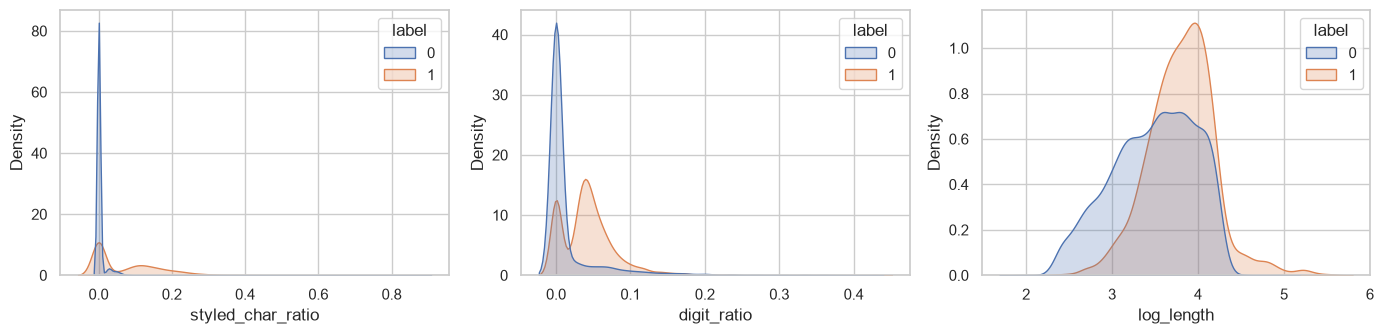

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ['styled_char_ratio', 'digit_ratio', 'log_length']):
    sns.kdeplot(data=df, x=col, hue='label', common_norm=False, fill=True, ax=ax, warn_singular=False)
plt.tight_layout()

## 5. Kata paling khas per kelas

In [11]:
from collections import Counter
def top_words(texts, n=20):
    return Counter(w for t in texts for w in t.split()).most_common(n)
pd.DataFrame({'judol': top_words(df[df.label == 1].text_norm), 'normal': top_words(df[df.label == 0].text_norm)})

,judol,normal
0,"(,, 1054)","(di, 461)"
1,"(alexis17, 739)","(user, 453)"
2,"(!, 584)","(yg, 377)"
3,"(., 580)","(bang, 351)"
4,"(di, 384)","(ini, 348)"
5,"(main, 365)","(nya, 342)"
6,"(banget, 314)","(ada, 283)"
7,"(gue, 304)","(😂, 263)"
8,"(gak, 292)","(yang, 262)"
9,"(udah, 258)","(ga, 239)"


Kata umum ("di", "yang") muncul di kedua kelas — TF-IDF otomatis menurunkan bobotnya. Nama situs (alexis17, pulau777, sgi88) hanya muncul di kelas judol.

## 6. Coba model yang sudah dilatih

Jalankan `python -m src.train` dulu dari root project.

In [12]:
from src.predict import predict
predict(['mantap videonya bang', 'gacor parah di 𝐒𝐆𝐈𝟖𝟖', 'k o i s l o t bikin aku sultan', 'harga mobilnya berapa ya?'])

[('mantap videonya bang', 'normal', 0.001363097485593013),
 ('gacor parah di 𝐒𝐆𝐈𝟖𝟖', 'judol', 0.9999258951406795),
 ('k o i s l o t bikin aku sultan', 'judol', 0.7370659511875897),
 ('harga mobilnya berapa ya?', 'normal', 0.0011317680131327664)]

## Kesimpulan EDA
- Buang `predicted_label` (leakage) dan duplikat **sebelum** split.
- Normalisasi Unicode wajib — tanpa itu 𝐒𝐆𝐈𝟖𝟖 dan SGI88 dianggap kata berbeda.
- Character n-gram + feature numerik (rasio huruf fancy, angka) sangat informatif.
- Pakai F1/precision/recall, bukan hanya accuracy.